In [3]:
import tensorflow as tf
print(tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [4]:
import zipfile
with zipfile.ZipFile("/content/archive.zip") as z:
    z.extractall("/content/data")
print("done")

done


In [5]:
import os
for root, dirs, files in os.walk("/content/data"):
    print(root, len(files))

/content/data 5
/content/data/Garbage classification 0
/content/data/Garbage classification/Garbage classification 0
/content/data/Garbage classification/Garbage classification/glass 501
/content/data/Garbage classification/Garbage classification/paper 594
/content/data/Garbage classification/Garbage classification/plastic 482
/content/data/Garbage classification/Garbage classification/trash 137
/content/data/Garbage classification/Garbage classification/metal 410
/content/data/Garbage classification/Garbage classification/cardboard 403
/content/data/garbage classification 0
/content/data/garbage classification/Garbage classification 0
/content/data/garbage classification/Garbage classification/glass 501
/content/data/garbage classification/Garbage classification/paper 594
/content/data/garbage classification/Garbage classification/plastic 482
/content/data/garbage classification/Garbage classification/trash 137
/content/data/garbage classification/Garbage classification/metal 410
/con

Classes: ['cardboard', 'glass', 'metal', 'paper', 'plastic', 'trash']
Total images: 2527
Train: 1768 | Val: 379 | Test: 380


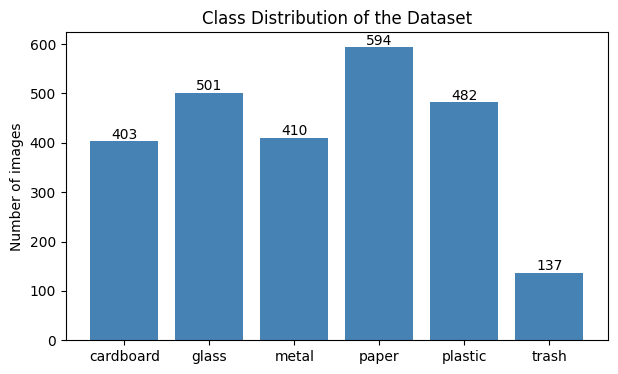

In [6]:
import os, random, numpy as np, tensorflow as tf
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split

SEED, IMG, BS = 42, 224, 32
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

DATA = "/content/data/Garbage classification/Garbage classification"
classes = sorted(os.listdir(DATA))
print("Classes:", classes)

paths, labels = [], []
for i, c in enumerate(classes):
    for f in os.listdir(f"{DATA}/{c}"):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            paths.append(f"{DATA}/{c}/{f}")
            labels.append(i)
paths, labels = np.array(paths), np.array(labels)
print("Total images:", len(paths))

# 70 / 15 / 15 split (stratified: har class ka ratio same rahega)
trp, tmp, trl, tml = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
vp, tp, vl, tl = train_test_split(tmp, tml, test_size=0.50, stratify=tml, random_state=SEED)
print("Train:", len(trp), "| Val:", len(vp), "| Test:", len(tp))

# Class distribution plot (report ke Section 7 ke liye)
counts = np.bincount(labels)
plt.figure(figsize=(7, 4))
bars = plt.bar(classes, counts, color="steelblue")
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width()/2, c + 5, str(c), ha="center")
plt.title("Class Distribution of the Dataset")
plt.ylabel("Number of images")
plt.savefig("class_distribution.png", dpi=200, bbox_inches="tight")
plt.show()

Class weights:
  cardboard: 1.04
  glass: 0.84
  metal: 1.03
  paper: 0.71
  plastic: 0.87
  trash: 3.07


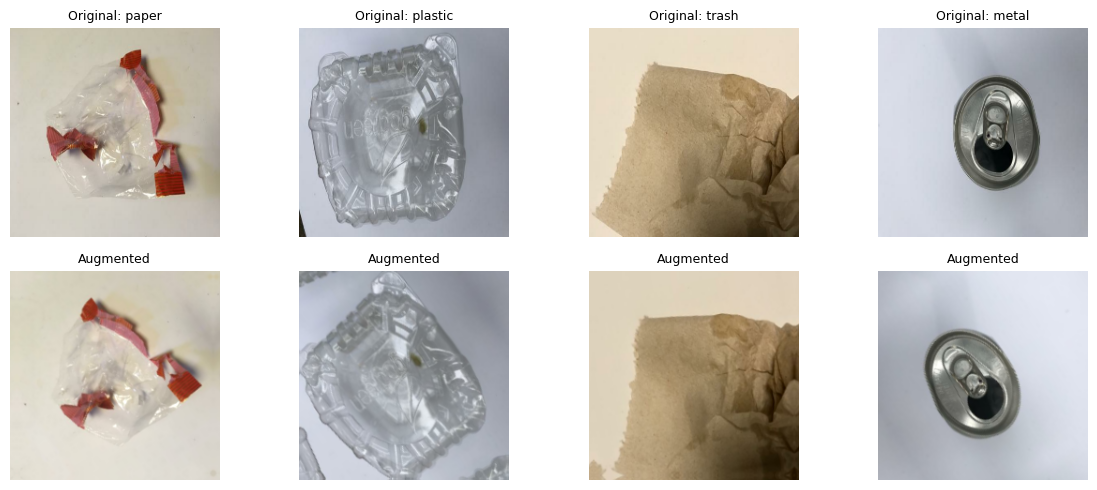

In [7]:
from tensorflow.keras import layers
from sklearn.utils.class_weight import compute_class_weight

# 1) Image load + resize (224x224)
def load(p, l):
    img = tf.io.read_file(p)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, (IMG, IMG))
    return img, l

def make_ds(p, l, train=False):
    d = tf.data.Dataset.from_tensor_slices((p, l))
    d = d.map(load, num_parallel_calls=tf.data.AUTOTUNE)
    if train:
        d = d.shuffle(1000, seed=SEED)
    return d.batch(BS).prefetch(tf.data.AUTOTUNE)

train_ds = make_ds(trp, trl, train=True)
val_ds   = make_ds(vp, vl)
test_ds  = make_ds(tp, tl)

# 2) Augmentation (sirf training ke time use hoga)
aug = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomBrightness(0.1),
], name="augmentation")

# 3) Class weights (chhoti class "trash" ko zyada importance)
cw = compute_class_weight("balanced", classes=np.unique(trl), y=trl)
class_weights = dict(enumerate(cw))
print("Class weights:")
for i, c in enumerate(classes):
    print(f"  {c}: {class_weights[i]:.2f}")

# 4) Augmentation ka before/after figure (report ke liye)
for imgs, lbls in train_ds.take(1):
    plt.figure(figsize=(12, 5))
    for i in range(4):
        plt.subplot(2, 4, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        plt.title(f"Original: {classes[lbls[i]]}", fontsize=9); plt.axis("off")
        plt.subplot(2, 4, i + 5)
        a = aug(tf.expand_dims(imgs[i], 0), training=True)[0]
        plt.imshow(np.clip(a.numpy(), 0, 255).astype("uint8"))
        plt.title("Augmented", fontsize=9); plt.axis("off")
    plt.tight_layout()
    plt.savefig("augmentation_samples.png", dpi=200, bbox_inches="tight")
    plt.show()

Model: "Custom_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 258,118 (1008.27 KB)

 Trainable params: 258,118 (1008.27 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 12s 98ms/step - accuracy: 0.2404 - loss: 1.7541 - val_accuracy: 0.3166 - val_loss: 1.5773 - learning_rate: 0.0010
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 16s 68ms/step - accuracy: 0.3111 - loss: 1.6355 - val_accuracy: 0.2559 - val_loss: 1.7012 - learning_rate: 0.0010
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 4s 62ms/step - accuracy: 0.3580 - loss: 1.5588 - val_accuracy: 0.3588 - val_loss: 1.5772 - learning_rate: 0.0010
Epoch 4/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 73ms/step - accuracy: 0.3835 - loss: 1.4776 - val_accuracy: 0.3931 - val_loss: 1.4187 - learning_rate: 0.0010
Epoch 5/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 66ms/step - accuracy: 0.4106 - loss: 1.4004 - val_accuracy: 0.3140 - val_loss: 1.4583 - learning_rate: 0.0010
Epoch 6/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 63ms/step - accuracy: 0.3988 - loss: 1.3897 - val_accuracy: 0.3879 - val_loss: 1.4427 - learning_rate: 0.0010
Epoch 7/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 71ms/step - accuracy: 0.4367 - loss: 1.3510 - val_a

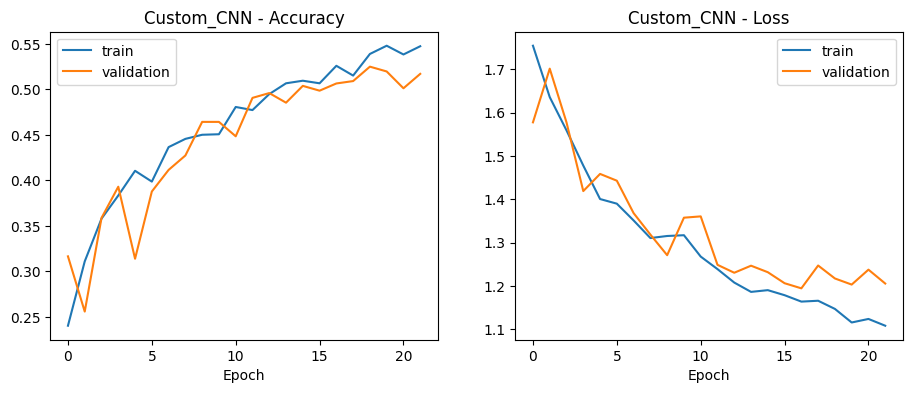

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.5026 - loss: 1.1707
Custom CNN Test Accuracy: 50.26%


In [8]:
import time
from tensorflow.keras import models

def build_cnn():
    inp = layers.Input((IMG, IMG, 3))
    x = aug(inp)                       # augmentation (sirf training mein active)
    x = layers.Rescaling(1/255)(x)     # pixels 0-1 mein
    for f in [32, 64, 128, 128]:
        x = layers.Conv2D(f, 3, padding="same", activation="relu")(x)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(128, activation="relu")(x)
    out = layers.Dense(len(classes), activation="softmax")(x)
    return models.Model(inp, out, name="Custom_CNN")

cnn = build_cnn()
cnn.summary()

cnn.compile(optimizer="adam",
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

cb = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

t0 = time.time()
h_cnn = cnn.fit(train_ds, validation_data=val_ds, epochs=30,
                class_weight=class_weights, callbacks=cb)
cnn_time = time.time() - t0
print(f"\nTraining time: {cnn_time/60:.1f} min")

# Training curves (report ke liye)
def plot_hist(h, name):
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(h.history["accuracy"], label="train")
    ax[0].plot(h.history["val_accuracy"], label="validation")
    ax[0].set_title(f"{name} - Accuracy"); ax[0].set_xlabel("Epoch"); ax[0].legend()
    ax[1].plot(h.history["loss"], label="train")
    ax[1].plot(h.history["val_loss"], label="validation")
    ax[1].set_title(f"{name} - Loss"); ax[1].set_xlabel("Epoch"); ax[1].legend()
    fig.savefig(f"curves_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()

plot_hist(h_cnn, "Custom_CNN")

# Test accuracy
loss, acc = cnn.evaluate(test_ds)
print(f"Custom CNN Test Accuracy: {acc*100:.2f}%")

cnn.save("custom_cnn.keras")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Frozen"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out (Dense)                     │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 15s 142ms/step - accuracy: 0.4440 - loss: 1.4532 - val_accuracy: 0.6649 - val_loss: 0.8788 - learning_rate: 0.0010
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 73ms/step - accuracy: 0.6821 - loss: 0.8914 - val_accuracy: 0.7467 - val_loss: 0.7092 - learning_rate: 0.0010
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 83ms/step - accuracy: 0.7319 - loss: 0.7381 - val_accuracy: 0.7784 - val_loss: 0.6072 - learning_rate: 0.0010
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 10s 87ms/step - accuracy: 0.7483 - loss: 0.6817 - val_accuracy: 0.7731 - val_loss: 0.6069 - learning_rate: 0.0010
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 85ms/step - accuracy: 0.7749 - loss: 0.6081 - val_accuracy: 0.8100 - val_loss: 0.5748 - learning_rate: 0.0010
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 77ms/step - accuracy: 0.7862 - loss: 0.5708 - val_accuracy: 0.8391 - val_loss: 0.5394 - learning_rate: 0.0010
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 75ms/step - accuracy: 0.7969 - loss: 0.5460 - val_

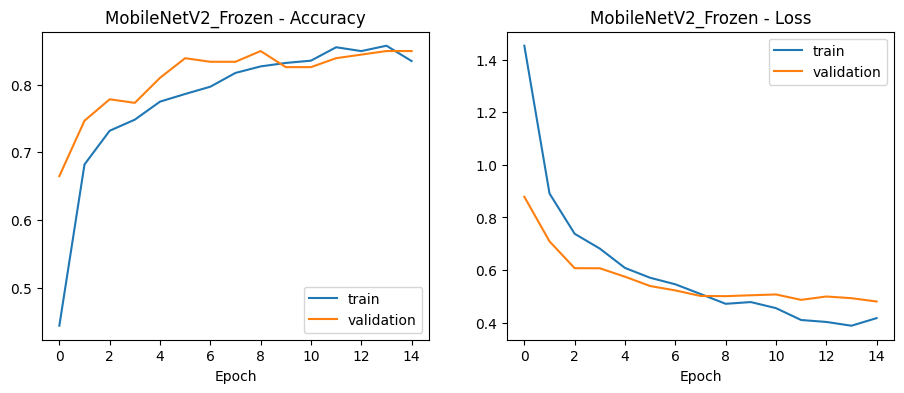

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 158ms/step - accuracy: 0.8763 - loss: 0.3849
MobileNetV2 (Frozen) Test Accuracy: 87.63%


In [9]:
base = tf.keras.applications.MobileNetV2(
    include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
base.trainable = False   # base ko freeze kiya

inp = layers.Input((IMG, IMG, 3))
x = aug(inp)
x = layers.Rescaling(1/127.5, offset=-1)(x)   # MobileNetV2 ko [-1, 1] range chahiye
x = base(x, training=False)
x = layers.GlobalAveragePooling2D(name="gap")(x)
x = layers.Dropout(0.3, name="drop")(x)
out = layers.Dense(len(classes), activation="softmax", name="out")(x)
mob = models.Model(inp, out, name="MobileNetV2_Frozen")
mob.summary()

mob.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])

t0 = time.time()
h_mob = mob.fit(train_ds, validation_data=val_ds, epochs=15,
                class_weight=class_weights, callbacks=cb)
mob_time = time.time() - t0
print(f"\nTraining time: {mob_time/60:.1f} min")

plot_hist(h_mob, "MobileNetV2_Frozen")

loss, acc = mob.evaluate(test_ds)
print(f"MobileNetV2 (Frozen) Test Accuracy: {acc*100:.2f}%")

mob.save("mobilenet_frozen.keras")   # fine-tuning se pehle backup

Model: "MobileNetV2_Frozen"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gap (GlobalAveragePooling2D)    │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ drop (Dropout)                  │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ out (Dense)                     │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 1,518,406 (5.79 MB)

 Non-trainable params: 747,264 (2.85 MB)

Epoch 1/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 14s 121ms/step - accuracy: 0.8490 - loss: 0.4017 - val_accuracy: 0.8549 - val_loss: 0.4576 - learning_rate: 1.0000e-05
Epoch 2/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 79ms/step - accuracy: 0.8563 - loss: 0.3475 - val_accuracy: 0.8575 - val_loss: 0.4467 - learning_rate: 1.0000e-05
Epoch 3/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 10s 78ms/step - accuracy: 0.8778 - loss: 0.3383 - val_accuracy: 0.8628 - val_loss: 0.4516 - learning_rate: 1.0000e-05
Epoch 4/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - accuracy: 0.8869 - loss: 0.3053 - val_accuracy: 0.8575 - val_loss: 0.4709 - learning_rate: 1.0000e-05
Epoch 5/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 84ms/step - accuracy: 0.8971 - loss: 0.2862 - val_accuracy: 0.8575 - val_loss: 0.4361 - learning_rate: 5.0000e-06
Epoch 6/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 78ms/step - accuracy: 0.8886 - loss: 0.2937 - val_accuracy: 0.8575 - val_loss: 0.4457 - learning_rate: 5.0000e-06
Epoch 7/20
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 87ms/step - accuracy: 0.88

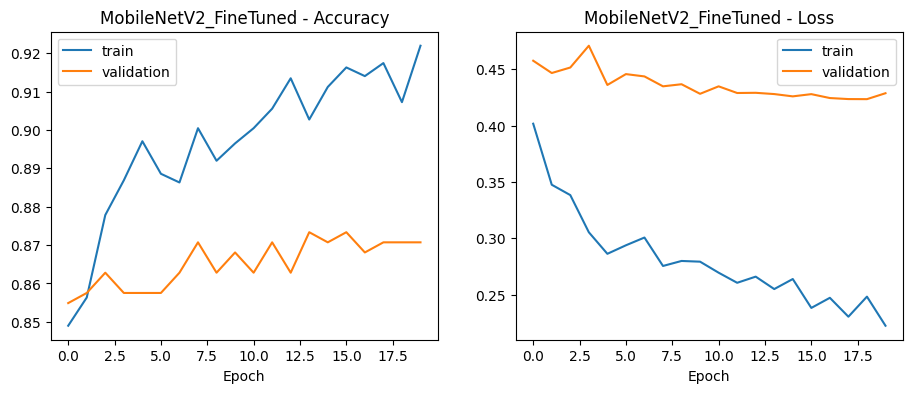

12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 53ms/step - accuracy: 0.8921 - loss: 0.3170
MobileNetV2 (Fine-tuned) Test Accuracy: 89.21%


In [10]:
# Aakhri 30 layers unfreeze, baaki frozen
base.trainable = True
for l in base.layers[:-30]:
    l.trainable = False
# BatchNorm layers ko frozen hi rakho (fine-tuning ke liye stable rehta hai)
for l in base.layers[-30:]:
    if isinstance(l, layers.BatchNormalization):
        l.trainable = False

# Recompile zaroori hai (nahi to change apply nahi hota)
mob.compile(optimizer=tf.keras.optimizers.Adam(1e-5),
            loss="sparse_categorical_crossentropy",
            metrics=["accuracy"])
mob.summary()

cb_ft = [
    tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2),
]

t0 = time.time()
h_ft = mob.fit(train_ds, validation_data=val_ds, epochs=20,
               class_weight=class_weights, callbacks=cb_ft)
ft_time = time.time() - t0
print(f"\nFine-tuning time: {ft_time/60:.1f} min")

plot_hist(h_ft, "MobileNetV2_FineTuned")

loss, acc = mob.evaluate(test_ds)
print(f"MobileNetV2 (Fine-tuned) Test Accuracy: {acc*100:.2f}%")

mob.save("mobilenet_finetuned.keras")


===== Custom_CNN =====
              precision    recall  f1-score   support

   cardboard      0.759     0.733     0.746        60
       glass      0.381     0.105     0.165        76
       metal      0.433     0.419     0.426        62
       paper      0.580     0.730     0.647        89
     plastic      0.698     0.411     0.517        73
       trash      0.209     0.900     0.340        20

    accuracy                          0.503       380
   macro avg      0.510     0.550     0.473       380
weighted avg      0.548     0.503     0.489       380



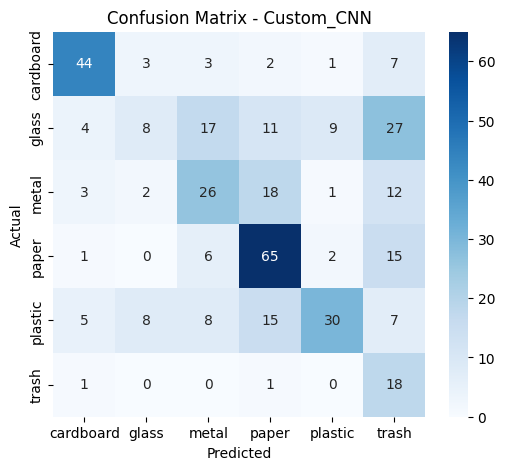


===== MobileNetV2_Frozen =====
              precision    recall  f1-score   support

   cardboard      0.933     0.933     0.933        60
       glass      0.848     0.882     0.865        76
       metal      0.822     0.968     0.889        62
       paper      0.939     0.865     0.901        89
     plastic      0.906     0.795     0.847        73
       trash      0.682     0.750     0.714        20

    accuracy                          0.876       380
   macro avg      0.855     0.865     0.858       380
weighted avg      0.881     0.876     0.876       380



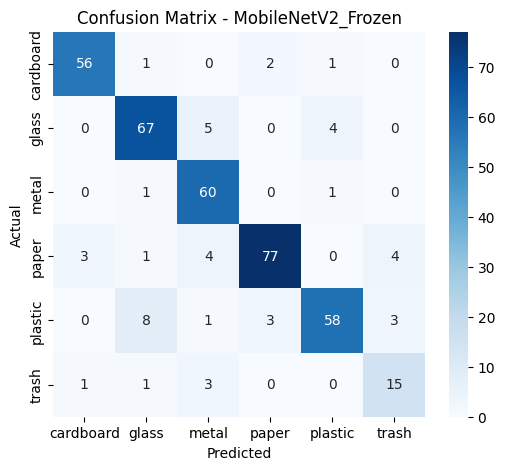


===== MobileNetV2_FineTuned =====
              precision    recall  f1-score   support

   cardboard      0.933     0.933     0.933        60
       glass      0.861     0.895     0.877        76
       metal      0.847     0.984     0.910        62
       paper      0.951     0.876     0.912        89
     plastic      0.938     0.822     0.876        73
       trash      0.696     0.800     0.744        20

    accuracy                          0.892       380
   macro avg      0.871     0.885     0.876       380
weighted avg      0.897     0.892     0.892       380



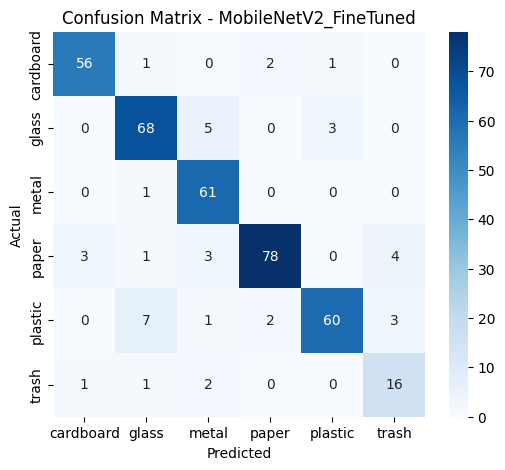


                        Accuracy  Macro Precision  Macro Recall  Macro F1  \
Custom_CNN                50.26            51.00         54.99     47.34   
MobileNetV2_Frozen        87.63            85.51         86.54     85.81   
MobileNetV2_FineTuned     89.21            87.09         88.50     87.56   

                       Total Params  
Custom_CNN                   258118  
MobileNetV2_Frozen          2265670  
MobileNetV2_FineTuned       2265670  


In [11]:
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support

# Frozen model wapas load karo (backup file se)
mob_frozen = tf.keras.models.load_model("mobilenet_frozen.keras")
mob_ft = mob   # fine-tuned

# Test set ke true labels (order same rehta hai kyunki test_ds shuffle nahi hua)
y_true = np.concatenate([y.numpy() for _, y in test_ds])

results = {}
def evaluate(model, name):
    y_pred = np.argmax(model.predict(test_ds, verbose=0), axis=1)
    print(f"\n===== {name} =====")
    print(classification_report(y_true, y_pred, target_names=classes, digits=3))
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=classes, yticklabels=classes)
    plt.xlabel("Predicted"); plt.ylabel("Actual")
    plt.title(f"Confusion Matrix - {name}")
    plt.savefig(f"cm_{name}.png", dpi=200, bbox_inches="tight")
    plt.show()
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro")
    acc = (y_pred == y_true).mean()
    results[name] = dict(acc=acc, p=p, r=r, f=f, params=model.count_params())
    return y_pred

pred_cnn = evaluate(cnn, "Custom_CNN")
pred_frz = evaluate(mob_frozen, "MobileNetV2_Frozen")
pred_ft  = evaluate(mob_ft, "MobileNetV2_FineTuned")

# Comparison table
import pandas as pd
df = pd.DataFrame(results).T
df.columns = ["Accuracy", "Macro Precision", "Macro Recall", "Macro F1", "Total Params"]
df[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]] = \
    (df[["Accuracy", "Macro Precision", "Macro Recall", "Macro F1"]] * 100).round(2)
df["Total Params"] = df["Total Params"].astype(int)
print("\n", df)
df.to_csv("model_comparison.csv")

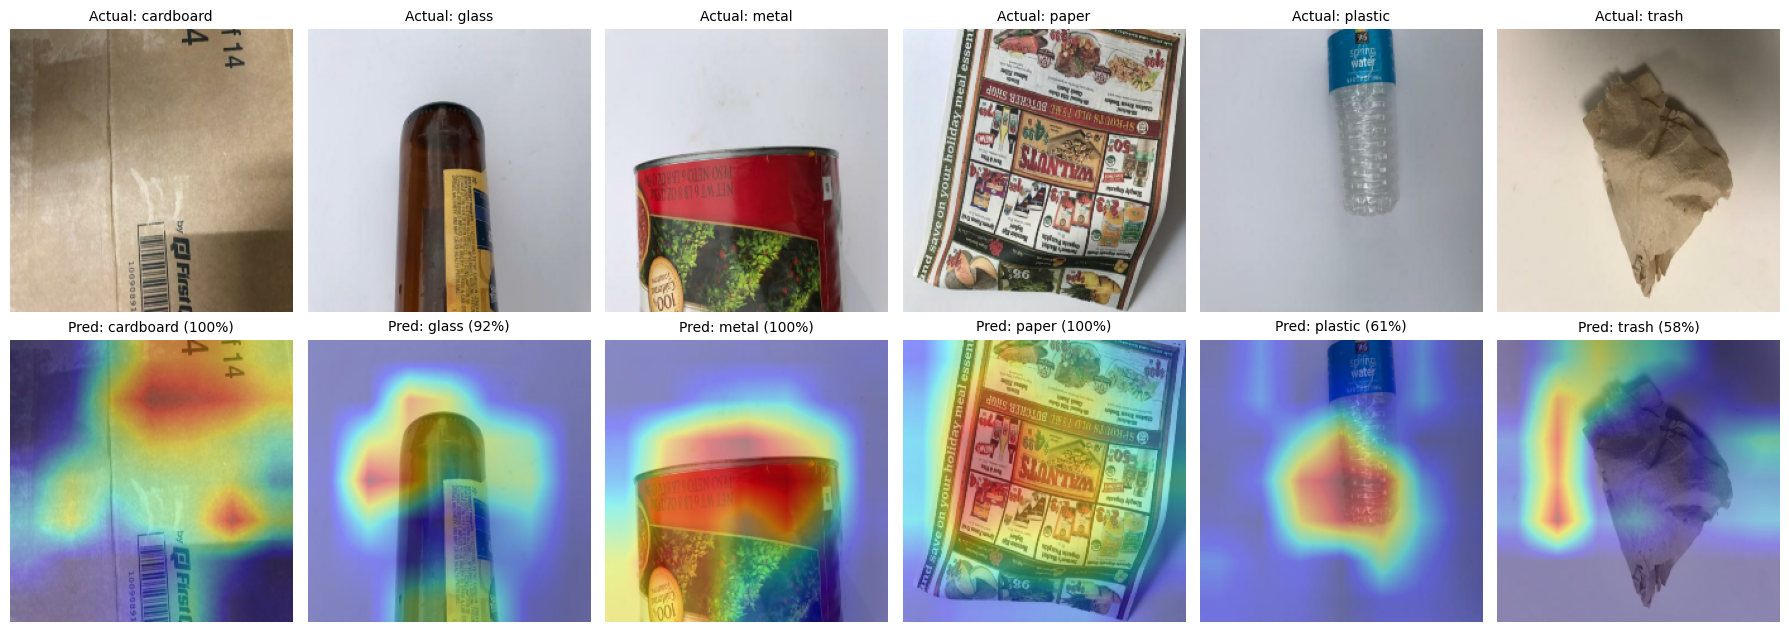

In [12]:
def gradcam(img, model, base_model, class_idx=None):
    x = tf.convert_to_tensor(img[None, ...], dtype=tf.float32)
    x = x / 127.5 - 1.0                        # MobileNetV2 ki range [-1, 1]
    with tf.GradientTape() as tape:
        conv = base_model(x, training=False)   # last conv feature maps
        tape.watch(conv)
        h = model.get_layer("gap")(conv)
        h = model.get_layer("drop")(h, training=False)
        preds = model.get_layer("out")(h)
        if class_idx is None:
            class_idx = int(tf.argmax(preds[0]))
        score = preds[:, class_idx]
    grads = tape.gradient(score, conv)
    weights = tf.reduce_mean(grads, axis=(1, 2))
    cam = tf.reduce_sum(conv * weights[:, None, None, :], axis=-1)[0]
    cam = tf.nn.relu(cam)
    cam = cam / (tf.reduce_max(cam) + 1e-8)
    return cam.numpy(), class_idx, preds[0].numpy()

def load_img(path):
    img = tf.io.read_file(path)
    img = tf.image.decode_jpeg(img, channels=3)
    return tf.image.resize(img, (IMG, IMG)).numpy()

def overlay(ax, img, cam):
    heat = tf.image.resize(cam[..., None], (IMG, IMG)).numpy()[..., 0]
    ax.imshow(img.astype("uint8"))
    ax.imshow(heat, cmap="jet", alpha=0.4)
    ax.axis("off")

# Har class ki ek sahi predicted image
rng = np.random.RandomState(SEED)
fig, axes = plt.subplots(2, 6, figsize=(18, 6.5))
for c, cname in enumerate(classes):
    idx = np.where((y_true == c) & (pred_ft == c))[0]
    i = rng.choice(idx)
    img = load_img(tp[i])
    cam, k, probs = gradcam(img, mob, base)
    axes[0, c].imshow(img.astype("uint8"))
    axes[0, c].set_title(f"Actual: {cname}", fontsize=10)
    axes[0, c].axis("off")
    overlay(axes[1, c], img, cam)
    axes[1, c].set_title(f"Pred: {classes[k]} ({probs[k]*100:.0f}%)", fontsize=10)
plt.tight_layout()
plt.savefig("gradcam_correct.png", dpi=200, bbox_inches="tight")
plt.show()

Galat predictions: 41 / 380
Average confidence (sahi predictions): 90.6%
Average confidence (galat predictions): 73.7%


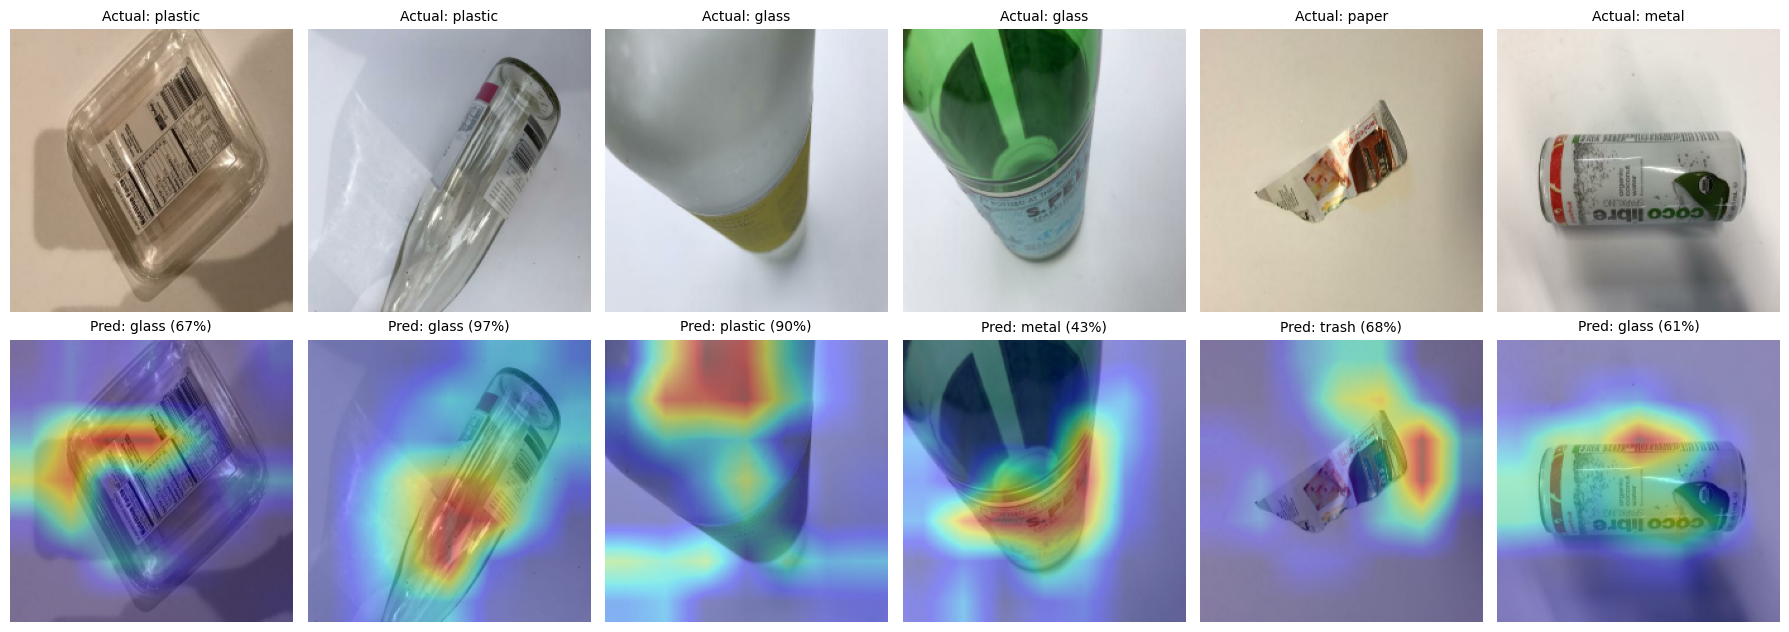

In [13]:
# 1) Sahi vs galat predictions par model kitna confident tha
probs_all = mob.predict(test_ds, verbose=0)
conf = probs_all.max(axis=1)
correct = (pred_ft == y_true)
print(f"Galat predictions: {(~correct).sum()} / {len(y_true)}")
print(f"Average confidence (sahi predictions): {conf[correct].mean()*100:.1f}%")
print(f"Average confidence (galat predictions): {conf[~correct].mean()*100:.1f}%")

# 2) Sabse common confusions ke examples
pairs = [("plastic","glass"), ("plastic","glass"), ("glass","plastic"),
         ("glass","metal"), ("paper","trash"), ("metal","glass")]
used, chosen = set(), []
for a, b in pairs:
    ia, ib = classes.index(a), classes.index(b)
    idx = [i for i in np.where((y_true == ia) & (pred_ft == ib))[0] if i not in used]
    if idx:
        used.add(idx[0]); chosen.append(idx[0])

fig, axes = plt.subplots(2, len(chosen), figsize=(3*len(chosen), 6.5), squeeze=False)
for col, i in enumerate(chosen):
    img = load_img(tp[i])
    cam, k, probs = gradcam(img, mob, base)
    axes[0, col].imshow(img.astype("uint8"))
    axes[0, col].set_title(f"Actual: {classes[y_true[i]]}", fontsize=10)
    axes[0, col].axis("off")
    overlay(axes[1, col], img, cam)
    axes[1, col].set_title(f"Pred: {classes[k]} ({probs[k]*100:.0f}%)", fontsize=10)
plt.tight_layout()
plt.savefig("misclassified_examples.png", dpi=200, bbox_inches="tight")
plt.show()

In [14]:
!ls /content
!ls /content/data

archive.zip			  custom_cnn.keras
augmentation_samples.png	  data
class_distribution.png		  gradcam_correct.png
cm_Custom_CNN.png		  misclassified_examples.png
cm_MobileNetV2_FineTuned.png	  mobilenet_finetuned.keras
cm_MobileNetV2_Frozen.png	  mobilenet_frozen.keras
curves_Custom_CNN.png		  model_comparison.csv
curves_MobileNetV2_FineTuned.png  sample_data
curves_MobileNetV2_Frozen.png
'garbage classification'	       one-indexed-files-notrash_val.txt
'Garbage classification'	       one-indexed-files.txt
 one-indexed-files-notrash_test.txt    zero-indexed-files.txt
 one-indexed-files-notrash_train.txt


In [15]:
!zip -q pbl_outputs.zip *.png *.csv *.keras
from google.colab import files
files.download("pbl_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>